# Lab 3 Nhận dạng năm lệnh tiếng Việt bằng Gaussian HMM

CSE457 · Tài liệu gốc: `Lab 3.pdf`, trang 6–10. Chạy tuần tự trong VS Code với kernel Conda đã có.

**Dữ liệu hoàn toàn tổng hợp bằng eSpeak Vietnamese**, không phải bản ghi người thật.
Accuracy ở đây chỉ áp dụng cho 10 WAV TTS cùng nguồn. Không dùng test để fit hoặc chọn cấu hình.
Cấu hình chính được chọn trước theo PDF: 5 states, 39D, diagonal covariance.

Mã tái sử dụng nằm trong `lab03.py`; notebook thực thi từng giai đoạn và hiển thị kết quả thật.
Các CSV/PNG/JSON được ghi trong `results/`; model GaussianHMM thật được lưu bằng joblib.

## 0 Kiểm tra môi trường

Trước khi cài thêm bất cứ gói nào, chạy trong terminal Conda:
```powershell
python --version
python -c "import sys; print(sys.executable)"
python -m pip --version
```
Lần chạy bàn giao dùng thư viện đã có trong Conda, không cài/nâng cấp base.
Jupyter metapackage không có metadata, nhưng ipykernel và jupyter_client hoạt động.
VS Code chạy notebook thông qua ipykernel. Không cần Colab hoặc venv.

In [1]:
from pathlib import Path
import sys
import time
from threadpoolctl import threadpool_limits
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'lab03.py').exists():
    ROOT = ROOT / 'Lab03_HMM'
assert (ROOT / 'lab03.py').exists(), 'Mở notebook từ thư mục dự án'
sys.path.insert(0, str(ROOT))
import lab03 as lab
import pandas as pd
import numpy as np
import joblib
thread_limit = threadpool_limits(limits=1)
environment = lab.setup()
print(sys.version)
print(sys.executable)
display(pd.DataFrame(environment['packages'].items(), columns=['Package', 'Version']))

3.13.12 | packaged by Anaconda, Inc. | (main, Feb 24 2026, 16:05:56) [MSC v.1942 64 bit (AMD64)]
C:\Users\vuhoa\miniconda3\python.exe


,Package,Version
0,numpy,2.4.2
1,scipy,1.17.1
2,matplotlib,3.10.8
3,librosa,1.0.0
4,soundfile,0.14.0
5,scikit-learn,1.7.1
6,hmmlearn,0.3.3
7,pandas,2.3.3
8,joblib,1.5.3
9,jupyter,metapackage chưa cài; dùng ipykernel trong VS ...


## A Chuẩn hóa và trích đặc trưng

Kiểm tra file, header WAV, hash byte và hash PCM, metadata, clipping và train/test overlap trước khi fit.
Không sửa dataset gốc. `repair_formats()` chỉ tạo bản sao ở thư mục khác nếu có sai định dạng.
Endpoint dùng ngưỡng năng lượng tương đối 30 dB; vùng giữ lại được tô trên waveform.
Pre-emphasis: $y[n]=x[n]-0.97x[n-1]$.

Mỗi frame có 13 MFCC (bao gồm c0), 13 delta và 13 delta², thành 39 chiều.
MFCC mô tả phổ; delta là tốc độ thay đổi; delta² là thay đổi của tốc độ.
25 ms window Hamming, hop 10 ms, FFT 512, 26 mel bands. Librosa center=True có padding ở biên.
CMVN từng utterance: $(X-\mu_X)/\max(\sigma_X,10^{-8})$, không dùng thống kê tổng hợp test.

,path,split,label,sr,channels,subtype,duration_s,peak,clipping_samples,leading_s,trailing_s,sha256,pcm_sha256,metadata_ok,format_ok
0,test/dong/dong_07.wav,test,dong,16000,1,PCM_16,0.753687,0.762238,0,0.313063,0.333000,d8bfbd77f117594eea57706f04fd90ef10360ecf8679bc...,b6802d6e64dbeb27b1554d10c940491410d77901c4669f...,True,True
1,test/dong/dong_08.wav,test,dong,16000,1,PCM_16,0.801625,0.768127,0,0.316063,0.333562,10760380c3e69b400063e11e8d30f30bb6cc5000ecb4d5...,d47c6e5b71594e6be83a4edd5a640824bdf54b1e822bdb...,True,True
2,test/dung/dung_07.wav,test,dung,16000,1,PCM_16,0.911312,0.752777,0,0.312000,0.331937,b82f984f7d55c04d1040844f62477cdf299a068765c961...,b0d89ad4c54e0c0b566c449f8122e6882b5bdac2e5f043...,True,True
3,test/dung/dung_08.wav,test,dung,16000,1,PCM_16,0.989125,0.765869,0,0.314937,0.331750,96b47e28ba9797367eb818dcc995a5ab9dcf72e7c01f71...,209580fba97999b95ca1bfc910ba011b8c0951a6141ce7...,True,True
4,test/len/len_07.wav,test,len,16000,1,PCM_16,0.871375,0.889984,0,0.300563,0.334062,5da191a94fba1636e0018079195ab0a6c555a30a668f03...,9be8c444c601aec7b39f8b5cf7aa08f778e4a4c4017669...,True,True
5,test/len/len_08.wav,test,len,16000,1,PCM_16,0.946313,0.889984,0,0.302375,0.334188,c2d2100b3c77607dec794090c4fe108d9783e50ddd4ccb...,baf0b1f9abd8d8df9bd8835275c321fd5e220ccf86a4e4...,True,True
6,test/mo/mo_07.wav,test,mo,16000,1,PCM_16,0.854187,0.889984,0,0.300187,0.333437,366f224c8501eecd1d3ca5da8be8ffa41c87dcfb108706...,fb3f1e226428da95284966506e6a05ad6bfb58b90e22bc...,True,True
7,test/mo/mo_08.wav,test,mo,16000,1,PCM_16,0.923625,0.889984,0,0.303438,0.333500,72e941d80b2e19d45eabc9c5aa85a4c5f59c2b2ee51efa...,a2295dc82c9dd81dc29b8bf6d814cf55fd1dff0fb69124...,True,True
8,test/xuong/xuong_07.wav,test,xuong,16000,1,PCM_16,0.897938,0.889984,0,0.311937,0.332500,4a9337f52d5f4dbb968d1dc9a7bb6be445c5a1c5eb4ef1...,ae7a47ac7b527ae90c20afb22f124309a896355c45a5b4...,True,True
9,test/xuong/xuong_08.wav,test,xuong,16000,1,PCM_16,0.964063,0.889984,0,0.314937,0.332062,0ec45ece667ed11e5ccff5a3a533268d718b93291f6bf7...,a1db7089610c5a8467d4812c9404c9a1539c1c28481c23...,True,True


{'files': 40, 'train': 30, 'test': 10, 'duplicates': [], 'fatal_errors': [], 'format_repairs_needed': 0, 'total_clipping_samples': 0, 'duration_min_s': 0.748375, 'duration_max_s': 0.989125, 'silence_note': 'PDF đề xuất 0.2–0.5 s đầu/cuối; xem leading_s/trailing_s đo gần đúng.', 'source': 'synthetic_tts / eSpeak Vietnamese; chưa xác minh nhãn bằng người nghe'}


,path,frames,dimensions
0,test/dong/dong_07.wav,14,39
1,test/dong/dong_08.wav,18,39
2,test/dung/dung_07.wav,29,39
3,test/dung/dung_08.wav,37,39
4,test/len/len_07.wav,26,39
5,test/len/len_08.wav,34,39
6,test/mo/mo_07.wav,25,39
7,test/mo/mo_08.wav,32,39
8,test/xuong/xuong_07.wav,28,39
9,test/xuong/xuong_08.wav,35,39


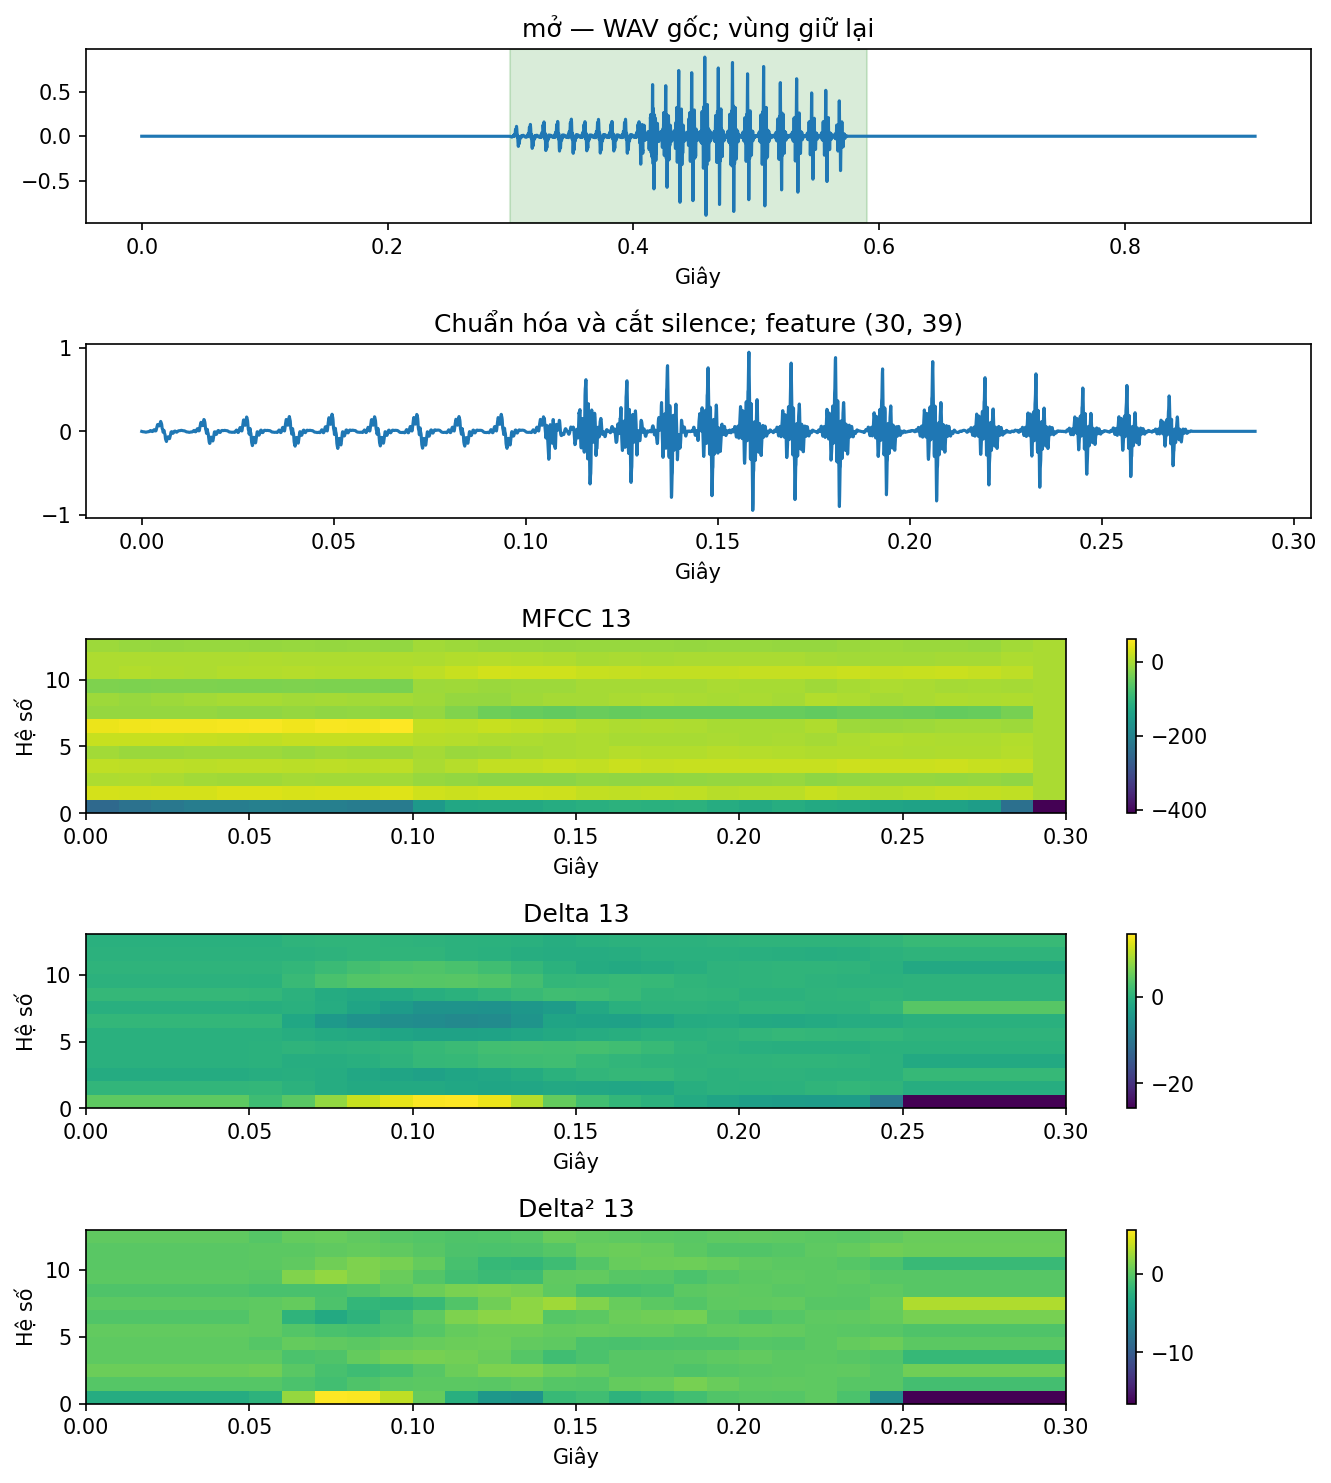

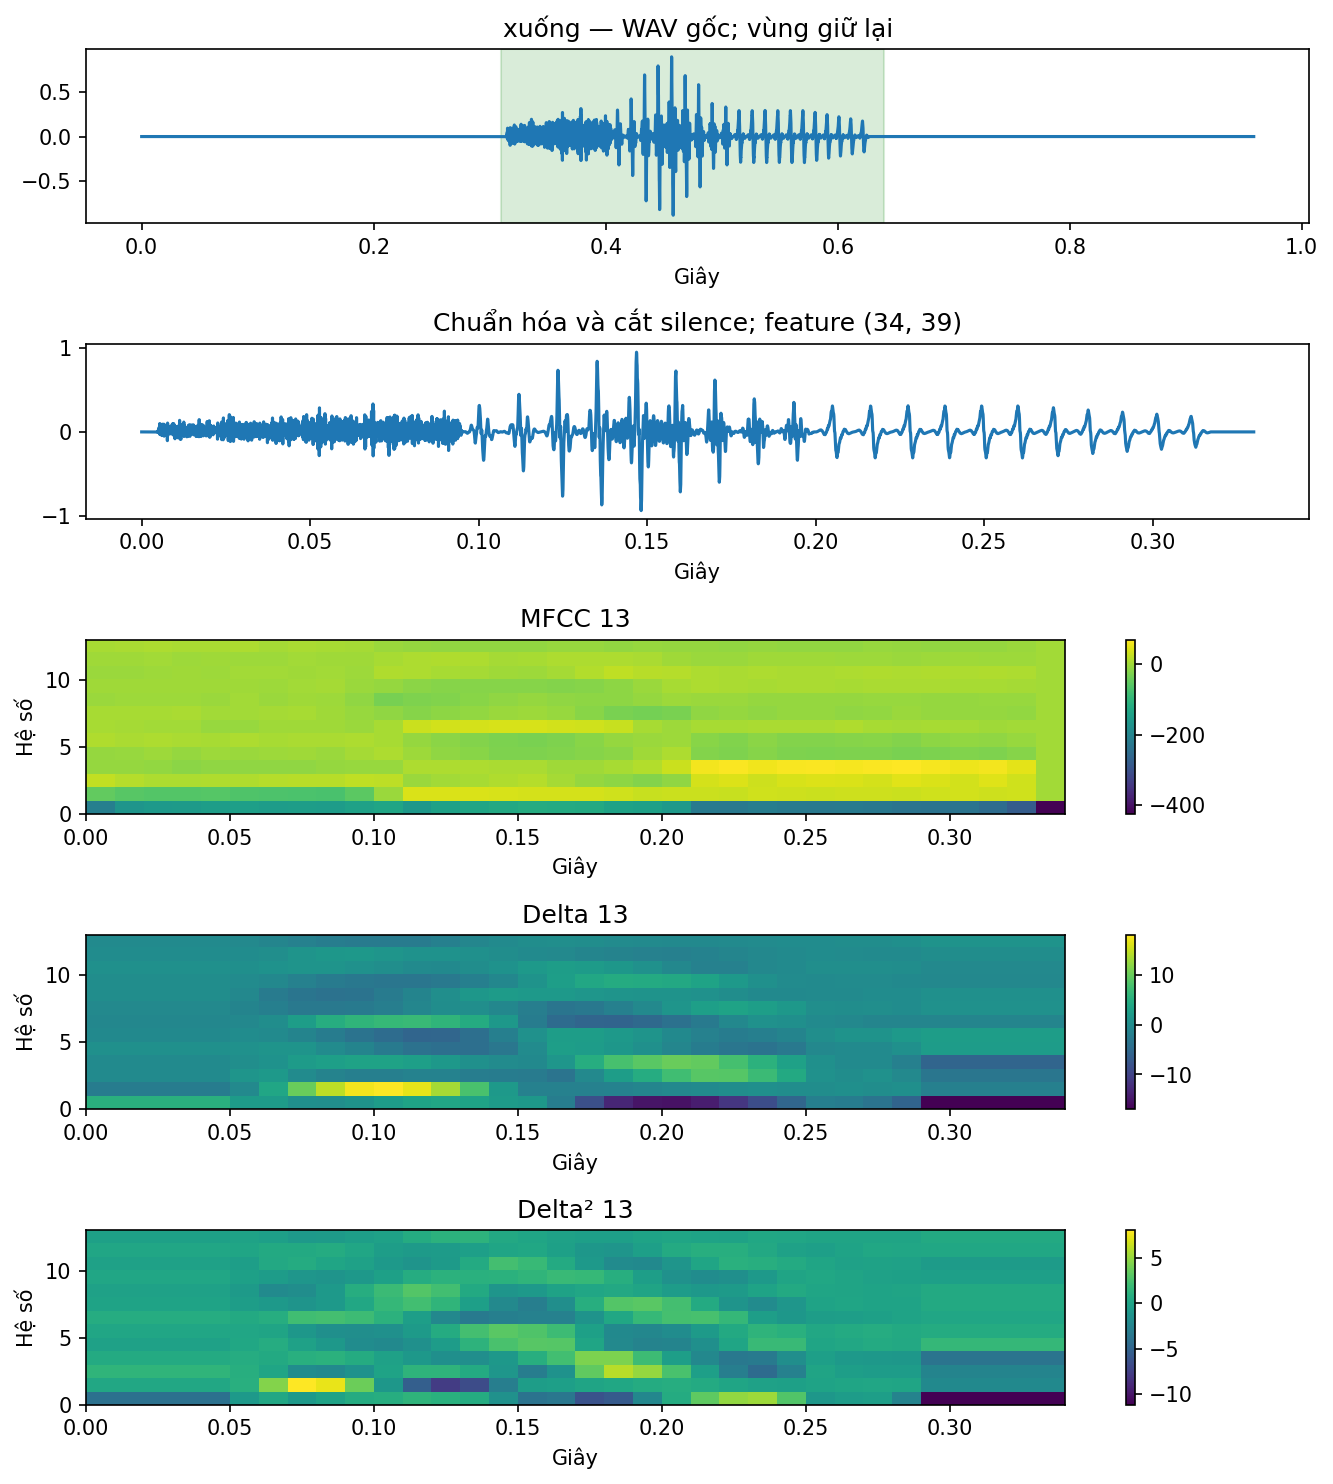

In [2]:
audit, audit_summary = lab.audit_data()
display(audit)
print(audit_summary)
cache, shapes = lab.feature_stage(audit)
display(shapes)
for label in ['mo', 'xuong']:
    display(Image(filename=str(ROOT / 'results/feature_plots' / f'{label}.png')))

## B Khởi tạo Gaussian HMM và C Baum Welch

$\lambda=(A,B,\pi)$: A là chuyển trạng thái, B là Gaussian phát xạ, π là phân bố bắt đầu.
π cố định [1,0,0,0,0]. A bắt đầu với self-loop 0.7, next-state 0.3, state cuối 1.
Chỉ cập nhật `t,m,c`; không khởi tạo lại π hoặc A. Gaussian được khởi tạo bằng chia đều thời gian của **train**.
Mỗi lớp fit `np.vstack(sequences)` với `lengths` của đúng 6 utterance.

Baum–Welch lặp Forward–Backward (E) và cập nhật kỳ vọng (M); chỉ đạt cực trị cục bộ.
Covariance có prior nhỏ để tránh suy biến. Sau fit kiểm tra π, tổng hàng, mọi chuyển cấm bằng 0.
Nếu topology không giữ được, fit lại với A cố định và ghi rõ fallback.
`monitor_.converged` có thể True khi hết 80 iteration; bảng ghi thêm `tolerance_met` và `stop_reason`.

,config,label,n_states,dimensions,covariance,files,frames,fit_s,iterations,monitor_converged,tolerance_met,stop_reason,last_improvement,min_initial_state_frames,train_score_per_frame,topology_ok,transition_fixed_fallback,warnings
0,baseline,mo,5,39,diag,6,158,0.262419,16,True,False,decreased,-0.001358,30,-17.762218,True,False,Model is not converging. Current: -2806.43036...
1,baseline,dong,5,39,diag,6,91,0.153859,6,True,False,decreased,-0.001076,16,-7.868228,True,False,Model is not converging. Current: -716.008721...
2,baseline,len,5,39,diag,6,176,0.197548,12,True,False,decreased,-0.013882,33,-21.092718,True,False,Model is not converging. Current: -3712.31844...
3,baseline,xuong,5,39,diag,6,184,0.166667,6,True,True,tolerance,0.000864,35,-18.033403,True,False,
4,baseline,dung,5,39,diag,6,192,0.160413,6,True,True,tolerance,0.000015,36,-19.989809,True,False,


mo π = [1. 0. 0. 0. 0.]
[[0.81818 0.18182 0.      0.      0.     ]
 [0.      0.78571 0.21429 0.      0.     ]
 [0.      0.      0.68421 0.31579 0.     ]
 [0.      0.      0.      0.875   0.125  ]
 [0.      0.      0.      0.      1.     ]]
dong π = [1. 0. 0. 0. 0.]
[[0.8     0.2     0.      0.      0.     ]
 [0.      0.40002 0.59998 0.      0.     ]
 [0.      0.      0.68421 0.31579 0.     ]
 [0.      0.      0.      0.33336 0.66664]
 [0.      0.      0.      0.      1.     ]]
len π = [1. 0. 0. 0. 0.]
[[0.86957 0.13043 0.      0.      0.     ]
 [0.      0.73913 0.26087 0.      0.     ]
 [0.      0.      0.875   0.125   0.     ]
 [0.      0.      0.      0.76001 0.23999]
 [0.      0.      0.      0.      1.     ]]
xuong π = [1. 0. 0. 0. 0.]
[[0.83332 0.16668 0.      0.      0.     ]
 [0.      0.85362 0.14638 0.      0.     ]
 [0.      0.      0.8334  0.1666  0.     ]
 [0.      0.      0.      0.85366 0.14634]
 [0.      0.      0.      0.      1.     ]]
dung π = [1. 0. 0. 0. 0.]
[[0.8285

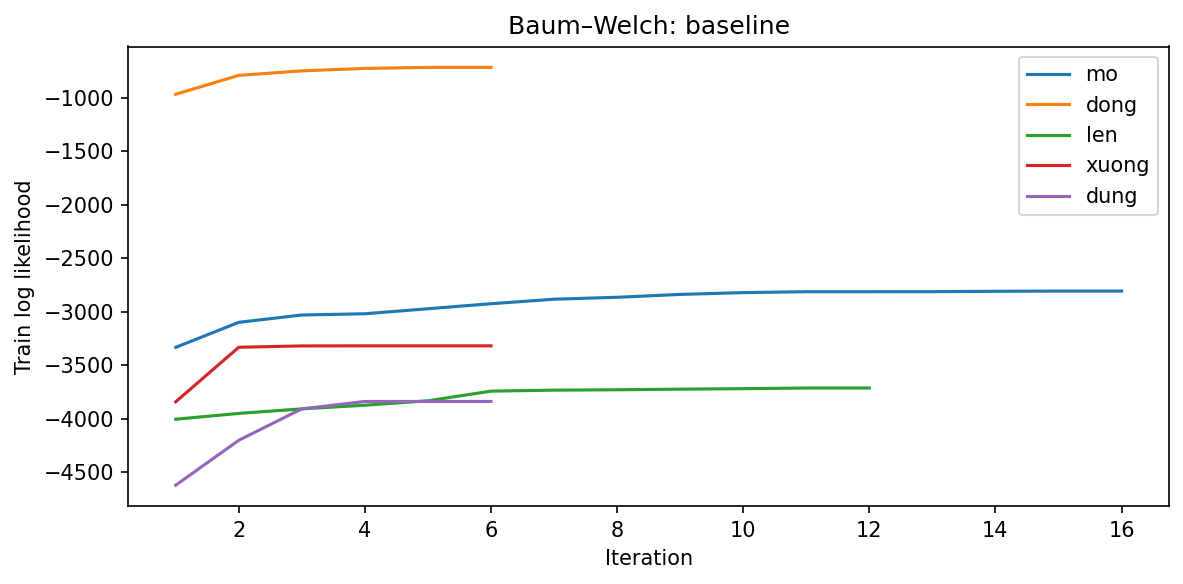

In [3]:
models, training, training_elapsed = lab.fit_models(audit, cache, persist=True)
display(training)
for label, model in models.items():
    lab.assert_topology(model)
    print(label, 'π =', model.startprob_)
    print(np.round(model.transmat_, 5))
display(Image(filename=str(ROOT / 'results/convergence/baseline.png')))

## D Nhận dạng và Viterbi

Forward cộng xác suất của **mọi** đường hợp lệ; `model.score(X)` trả log likelihood.
Viterbi dùng max và backpointer để lấy **một** đường tốt nhất; log probability của đường không lớn hơn Forward.
Cùng utterance có cùng T cho cả 5 model, nên chia T không đổi argmax.
Gap top-1/top-2 phản ánh mức phân biệt của bộ model, không phải xác suất đúng được hiệu chuẩn.
`recognize(wav_path, models)` trả từ tiếng Việt, scores và xếp hạng.
Hai state path bên dưới dùng model nhãn thật; state là đoạn âm học ẩn, không mặc định tương ứng phone.

,path,truth,predicted,predicted_word,top2,correct,frames,score_top1,score_top2,gap,gap_per_frame,true_score_per_frame,prediction_ms,score_mo,score_dong,score_len,score_xuong,score_dung
0,test/dong/dong_07.wav,dong,dong,đóng,xuong,True,14,-164.052647,-2698.320666,2534.268019,181.019144,-11.718046,6.5641,-2758.668958,-164.052647,-4808.065674,-2698.320666,-3672.761462
1,test/dong/dong_08.wav,dong,dong,đóng,xuong,True,18,-1368.406548,-3036.775594,1668.369047,92.687169,-76.022586,5.0540,-3536.168970,-1368.406548,-6004.645663,-3036.775594,-3887.340549
2,test/dung/dung_07.wav,dung,dung,dừng,xuong,True,29,-968.493964,-3348.109116,2379.615152,82.055695,-33.396344,6.1475,-5099.241413,-10424.186958,-7288.996718,-3348.109116,-968.493964
3,test/dung/dung_08.wav,dung,dung,dừng,xuong,True,37,-973.843230,-4210.302961,3236.459730,87.471885,-26.320087,5.5438,-6449.213416,-11007.696897,-8712.769691,-4210.302961,-973.843230
4,test/len/len_07.wav,len,len,lên,xuong,True,26,-605.885834,-3976.154238,3370.268404,129.625708,-23.303301,4.6347,-4592.676272,-9783.195685,-605.885834,-3976.154238,-4480.645582
5,test/len/len_08.wav,len,len,lên,xuong,True,34,-904.102160,-4989.424837,4085.322677,120.156549,-26.591240,5.6572,-5997.625348,-8731.737886,-904.102160,-4989.424837,-5542.021636
6,test/mo/mo_07.wav,mo,mo,mở,dung,True,25,-589.938249,-4695.065112,4105.126863,164.205075,-23.597530,4.8470,-589.938249,-7093.904552,-6244.453542,-4906.176329,-4695.065112
7,test/mo/mo_08.wav,mo,mo,mở,xuong,True,32,-1050.699564,-5676.136045,4625.436481,144.544890,-32.834361,4.6239,-1050.699564,-7958.772938,-8211.695426,-5676.136045,-6288.090725
8,test/xuong/xuong_07.wav,xuong,xuong,xuống,dung,True,28,-500.882873,-3558.359478,3057.476605,109.195593,-17.888674,4.6155,-4931.446256,-8214.761718,-6474.928806,-500.882873,-3558.359478
9,test/xuong/xuong_08.wav,xuong,xuong,xuống,dung,True,35,-894.616028,-4347.388477,3452.772449,98.650641,-25.560458,4.5484,-6067.796720,-9193.864371,-7907.205885,-894.616028,-4347.388477


Clean accuracy: 1.0
('mở', {'mo': -589.9382492784858, 'dong': -7093.90455165926, 'len': -6244.453542396219, 'xuong': -4906.176328969426, 'dung': -4695.065112190291}, ['mo', 'dung', 'xuong', 'len', 'dong'])


,path,model,state,frames,duration_ms,viterbi_logp,forward_logp
0,test/mo/mo_07.wav,mo,0,5,50,-589.938249,-589.938249
1,test/mo/mo_07.wav,mo,1,4,40,-589.938249,-589.938249
2,test/mo/mo_07.wav,mo,2,4,40,-589.938249,-589.938249
3,test/mo/mo_07.wav,mo,3,7,70,-589.938249,-589.938249
4,test/mo/mo_07.wav,mo,4,5,50,-589.938249,-589.938249
5,test/xuong/xuong_07.wav,xuong,0,5,50,-500.882873,-500.882873
6,test/xuong/xuong_07.wav,xuong,1,7,70,-500.882873,-500.882873
7,test/xuong/xuong_07.wav,xuong,2,5,50,-500.882873,-500.882873
8,test/xuong/xuong_07.wav,xuong,3,6,60,-500.882873,-500.882873
9,test/xuong/xuong_07.wav,xuong,4,5,50,-500.882873,-500.882873


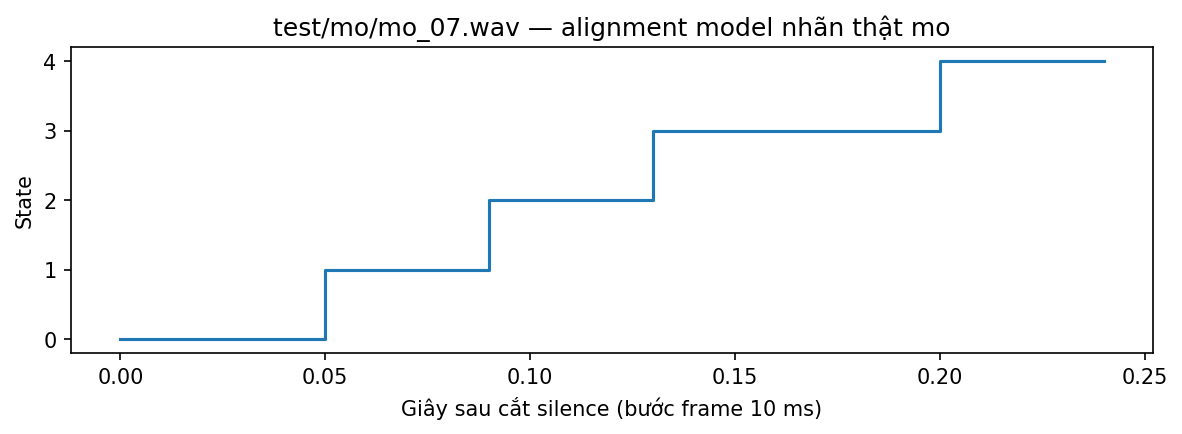

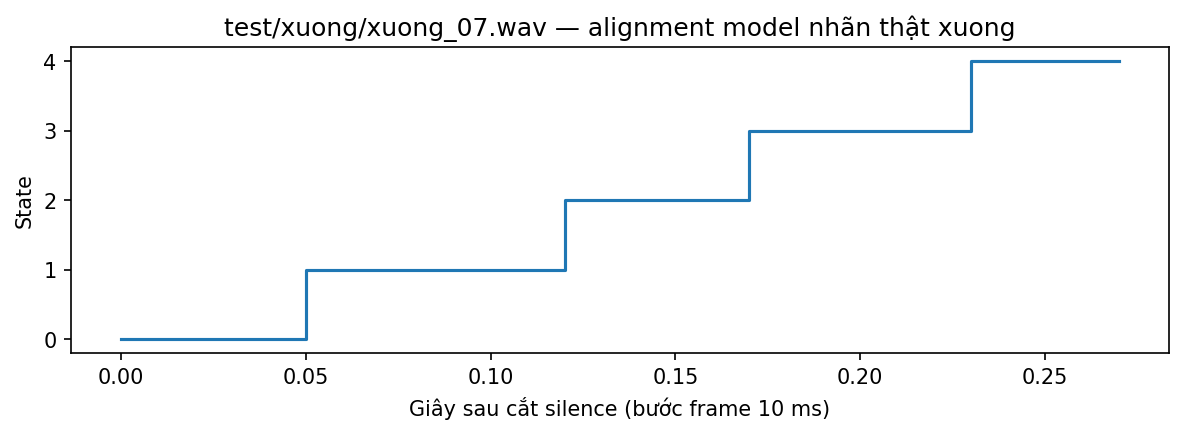

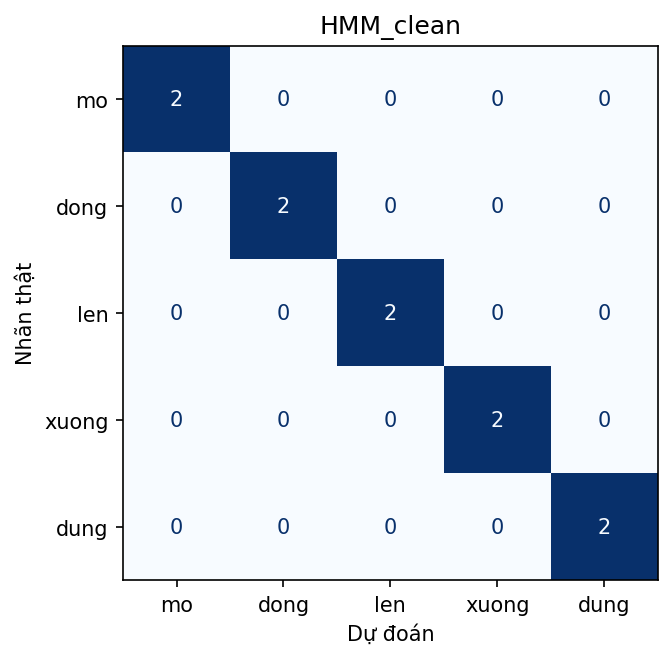

In [4]:
predictions = lab.evaluate(audit, models, cache)
predictions.to_csv(ROOT/'results/predictions.csv', index=False, encoding='utf-8-sig')
lab.table(predictions.head(3), 'likelihood_examples')
display(predictions)
print('Clean accuracy:', predictions.correct.mean())
print(lab.recognize(ROOT/'dataset/test/mo/mo_07.wav', models))
occupancy = lab.viterbi_stage(audit, cache, models)
display(occupancy)
for label in ['mo', 'xuong']:
    display(Image(filename=str(ROOT/'results/viterbi_plots'/f'{label}.png')))
display(Image(filename=str(ROOT/'results/confusion_matrices/HMM_clean.png')))

## E So sánh DTW và H Đánh giá robustness qua E1 đến E5

E1 thay số state 3/5/7; E2 thay số chiều 13/39; E3 thay diag/full, các lựa chọn khác giữ nguyên.
Full covariance là stress test có regularization; nhiều frame tương quan không tương đương nhiều utterance độc lập.
So sánh train/test score chỉ trong cùng chiều và cùng phép chuẩn hóa; không suy overfit từ score cao đơn thuần.

E4 dùng DTW13 kiểu Lab 2 và DTW39 để so sánh công bằng với HMM39 khi chỉ đổi recognizer.
DTW tìm template gần nhất trong 30 mẫu, Euclid và chi phí chia chiều dài đường.
Không có mã Lab 2 được cung cấp, nên đây là baseline tái xây dựng.
Thời gian dự đoán gồm đọc file, trích đặc trưng và scoring, một thread sau warm-up.
Thời gian chuẩn bị DTW chỉ lưu template; thời gian trích đặc trưng train dùng chung chưa tính vào hai bên.

E5 thêm Gaussian noise SNR 20 dB trước trim và giảm gain còn 0.3, không fit lại model.
Time-stretch 0.8/1.2 kiểm tra thay đổi tốc độ nhân tạo, không phải người nói mới.
Các điều kiện noise/gain là environment/channel mismatch. Chưa có speaker mismatch.
Không dùng kết quả test E1–E3 để thay cấu hình chính.

C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-pac

C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-pac

C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\vuhoa\miniconda3\Lib\site-pac

...

E4_paired_cases


,path,truth,predicted_HMM,predicted_DTW
0,test/dong/dong_07.wav,dong,dong,dong
1,test/dong/dong_08.wav,dong,dong,dong
2,test/dung/dung_07.wav,dung,dung,dung
3,test/dung/dung_08.wav,dung,dung,dung
4,test/len/len_07.wav,len,len,len
5,test/len/len_08.wav,len,len,len
6,test/mo/mo_07.wav,mo,mo,mo
7,test/mo/mo_08.wav,mo,mo,mo
8,test/xuong/xuong_07.wav,xuong,xuong,xuong
9,test/xuong/xuong_08.wav,xuong,xuong,xuong


Các WAV dự đoán sai:


,path,truth,predicted,predicted_word,top2,correct,frames,score_top1,score_top2,gap,gap_per_frame,true_score_per_frame,prediction_ms,score_mo,score_dong,score_len,score_xuong,score_dung


,mo,dong,len,xuong,dung,accuracy,macro avg,weighted avg
precision,1,1,1,1,1,1,1,1
recall,1,1,1,1,1,1,1,1
f1-score,1,1,1,1,1,1,1,1
support,2,2,2,2,2,1,10,10


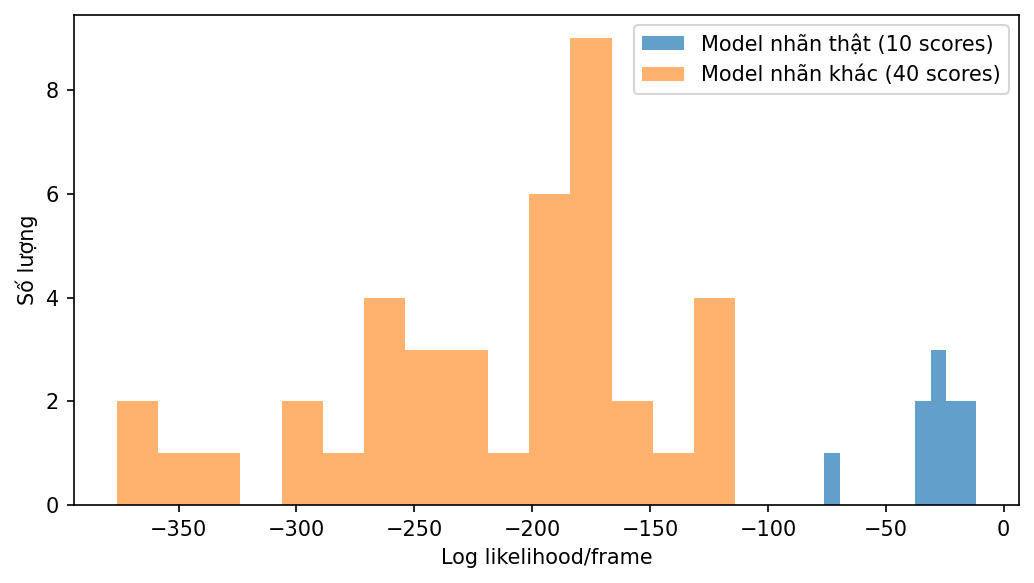

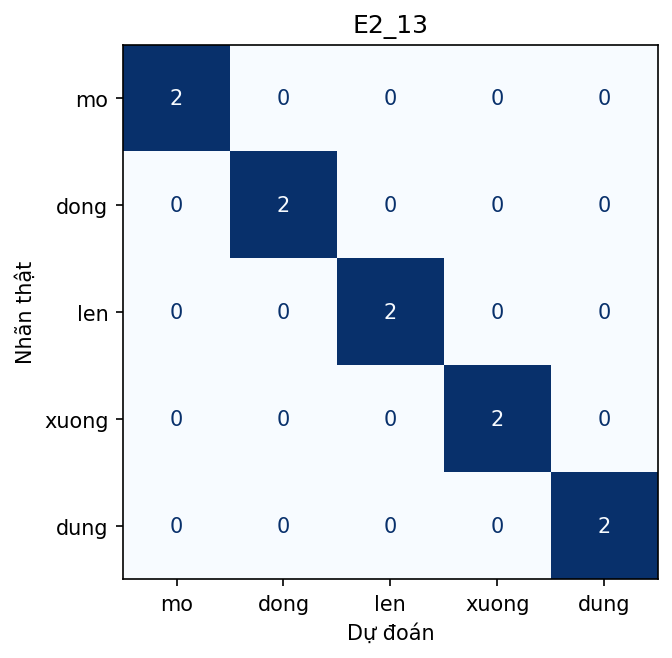

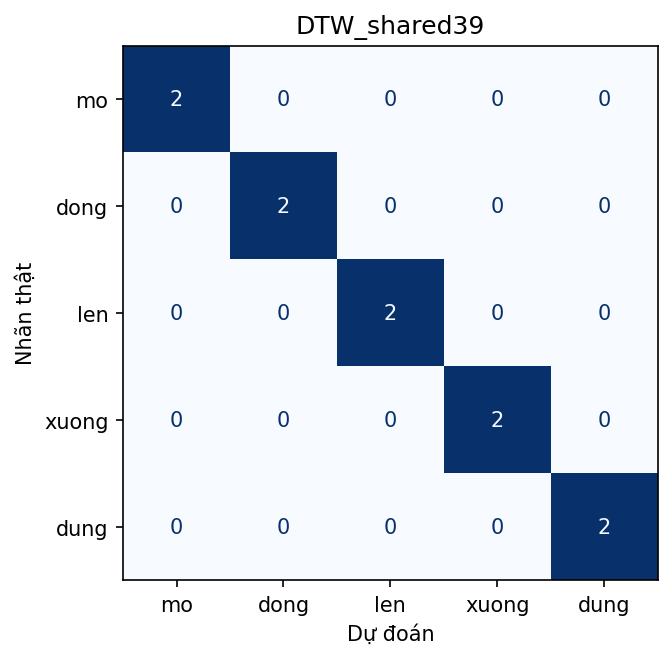

In [5]:
configurations, comparison, robustness = lab.experiment_stage(
    audit, cache, models, training, predictions, training_elapsed)
for name in ['E1', 'E2', 'E3', 'E4', 'E5', 'speed_robustness', 'E4_paired_cases']:
    print(name)
    display(pd.read_csv(ROOT/'results/experiment_tables'/f'{name}.csv'))
print('Các WAV dự đoán sai:')
display(predictions.loc[~predictions.correct])
display(pd.read_json(ROOT/'results/HMM_clean_classification_report.json'))
lab.score_plot(predictions)
display(Image(filename=str(ROOT/'results/score_distribution.png')))
display(Image(filename=str(ROOT/'results/confusion_matrices/E2_13.png')))
display(Image(filename=str(ROOT/'results/confusion_matrices/DTW_shared39.png')))

## F Lexicon mini

Chưa có phone inventory của giảng viên. Lexicon minh họa dùng token WW_* đại diện toàn từ giả lập,
**không phải phiên âm chuẩn và không phải phone inventory**. Parser vẫn đọc đúng định dạng WORD UNIT ...
Whole-word HMM ánh xạ thẳng nhãn → model nên không cần lexicon để chấm 5 từ đã biết.
Với phone HMM, lexicon cung cấp chuỗi phone; nối các model theo thứ tự phát âm,
chuyển từ state cuối phone trước sang state đầu phone sau, điều chỉnh xác suất exit/self-loop,
có thể thêm silence/biến thể phát âm. Không nối các absorbing state nguyên trạng vì không thể thoát phone.
Chưa huấn luyện phone HMM.

## G Bigram MAP và E6 Language Model

Corpus lệnh tự xây dựng, tokenize theo khoảng trắng, ánh xạ lệnh tiếng Việt sang nhãn nội bộ.
Đếm cả `<s>` và `</s>`; tập đích V gồm 5 lệnh và `</s>`.
Mẫu số là số outgoing bigram từ context, đảm bảo tổng xác suất bằng 1.
$P(w|h)=[C(h,w)+k]/[C_{out}(h)+kV]$, k=0.5.
$S(w)=\log P(X|\lambda_w)/T + \lambda_{LM}\log P(w|h)$, λ = 0, 0.1, 0.3, 1.

Không có chuỗi lệnh đã thu, nên context h được giả định và **không báo accuracy LM như test có context thật**.
Định nghĩa acoustic gần nhau trước khi xem kết quả là gap/frame <0.5.
Ví dụ điểm nhân tạo được lưu riêng với nhãn ARTIFICIAL_SCORES_NOT_WAV để minh họa quyết định đổi do LM.
LM chỉ hỗ trợ nếu context đáng tin và corpus phù hợp; λ quá lớn có thể làm sai acoustic đang đúng.

In [6]:
lexicon, lm_summary = lab.language_stage(predictions)
print('Parser:', lexicon)
display(pd.read_csv(ROOT/'language_model/unigram_counts.csv'))
display(pd.read_csv(ROOT/'language_model/bigram_counts.csv').head(18))
display(lm_summary)
display(pd.read_csv(ROOT/'results/experiment_tables/E6_LM_scores.csv').head(20))
display(pd.read_csv(ROOT/'results/experiment_tables/E6_changed_decisions.csv'))
display(pd.read_csv(ROOT/'results/experiment_tables/E6_artificial_illustration.csv'))
print((ROOT/'language_model/notes.json').read_text(encoding='utf-8'))

Parser: {'mở': ['WW_MO'], 'đóng': ['WW_DONG'], 'lên': ['WW_LEN'], 'xuống': ['WW_XUONG'], 'dừng': ['WW_DUNG']}


,token,count
0,</s>,12
1,<s>,12
2,dong,7
3,dung,8
4,len,6
5,mo,7
6,xuong,6


,previous,current,count,probability
0,<s>,mo,4,0.300000
1,<s>,dong,3,0.233333
2,<s>,len,2,0.166667
3,<s>,xuong,1,0.100000
4,<s>,dung,2,0.166667
5,<s>,</s>,0,0.033333
6,mo,mo,0,0.050000
7,mo,dong,1,0.150000
8,mo,len,4,0.450000
9,mo,xuong,0,0.050000


,lm_weight,trials,changed_decisions
0,0.0,60,0
1,0.1,60,0
2,0.3,60,0
3,1.0,60,0


,path,truth,previous,lm_weight,candidate,acoustic_score_per_frame,lm_logprob,total_score,prediction,acoustic_prediction,changed,hypothetical_context
0,test/dong/dong_07.wav,dong,<s>,0.0,mo,-197.047783,-1.203973,-197.047783,dong,dong,False,True
1,test/dong/dong_07.wav,dong,<s>,0.0,dong,-11.718046,-1.455287,-11.718046,dong,dong,False,True
2,test/dong/dong_07.wav,dong,<s>,0.0,len,-343.433262,-1.791759,-343.433262,dong,dong,False,True
3,test/dong/dong_07.wav,dong,<s>,0.0,xuong,-192.737190,-2.302585,-192.737190,dong,dong,False,True
4,test/dong/dong_07.wav,dong,<s>,0.0,dung,-262.340104,-1.791759,-262.340104,dong,dong,False,True
5,test/dong/dong_07.wav,dong,<s>,0.1,mo,-197.047783,-1.203973,-197.168180,dong,dong,False,True
6,test/dong/dong_07.wav,dong,<s>,0.1,dong,-11.718046,-1.455287,-11.863575,dong,dong,False,True
7,test/dong/dong_07.wav,dong,<s>,0.1,len,-343.433262,-1.791759,-343.612438,dong,dong,False,True
8,test/dong/dong_07.wav,dong,<s>,0.1,xuong,-192.737190,-2.302585,-192.967449,dong,dong,False,True
9,test/dong/dong_07.wav,dong,<s>,0.1,dung,-262.340104,-1.791759,-262.519280,dong,dong,False,True


,path,truth,previous,lm_weight,candidate,acoustic_score_per_frame,lm_logprob,total_score,prediction,acoustic_prediction,changed,hypothetical_context


,source,previous,lm_weight,candidate,acoustic,lm_logprob,total,prediction
0,ARTIFICIAL_SCORES_NOT_WAV,mo,0.0,mo,-20.00,-2.995732,-20.000000,mo
1,ARTIFICIAL_SCORES_NOT_WAV,mo,0.0,dong,-20.05,-1.897120,-20.050000,mo
2,ARTIFICIAL_SCORES_NOT_WAV,mo,0.0,len,-20.10,-0.798508,-20.100000,mo
3,ARTIFICIAL_SCORES_NOT_WAV,mo,0.0,xuong,-22.00,-2.995732,-22.000000,mo
4,ARTIFICIAL_SCORES_NOT_WAV,mo,0.0,dung,-23.00,-2.995732,-23.000000,mo
5,ARTIFICIAL_SCORES_NOT_WAV,mo,0.1,mo,-20.00,-2.995732,-20.299573,len
6,ARTIFICIAL_SCORES_NOT_WAV,mo,0.1,dong,-20.05,-1.897120,-20.239712,len
7,ARTIFICIAL_SCORES_NOT_WAV,mo,0.1,len,-20.10,-0.798508,-20.179851,len
8,ARTIFICIAL_SCORES_NOT_WAV,mo,0.1,xuong,-22.00,-2.995732,-22.299573,len
9,ARTIFICIAL_SCORES_NOT_WAV,mo,0.1,dung,-23.00,-2.995732,-23.299573,len


{
  "corpus_source": "Tự xây dựng, không có context âm thanh thực",
  "smoothing_k": 0.5,
  "vocabulary": [
    "mo",
    "dong",
    "len",
    "xuong",
    "dung",
    "</s>"
  ],
  "close_criterion": "gap/frame < 0.5; chốt trước đánh giá",
  "close_test_files": [],
  "lexicon_status": "minh họa WW_*; chờ inventory giảng viên"
}


## H Đề xuất reject và kiểm tra lưu mô hình

Argmax luôn chọn một trong 5 lớp dù đầu vào ngoài từ vựng.
Đề xuất reject khi top1/frame thấp hoặc gap/frame nhỏ. Ngưỡng phân vị train ở đây chỉ là heuristic in-sample,
không phải ngưỡng đã xác minh. Cần validation độc lập, từ OOV và silence/noise để đo false reject/false accept.
CMVN và chuẩn hóa peak có thể giúp bất biến gain; không chứng minh chịu được mọi channel.
10 test ⇒ mỗi file làm accuracy đổi 10 điểm phần trăm, kết luận cần thận trọng.

In [7]:
reject_proposal = lab.reject_proposal(audit, cache, models)
print(reject_proposal)
for label in lab.LABELS:
    loaded = joblib.load(ROOT/'models'/f'hmm_{label}.joblib')
    lab.assert_topology(loaded)
    test_f = cache[f'test/{label}/{label}_07.wav']
    assert np.isclose(loaded.score(test_f), models[label].score(test_f))
print('5 mô hình load lại và cho cùng score; topology hợp lệ.')
lab.save_json(dict(status='completed', clean_accuracy=float(predictions.correct.mean()),
    clean_correct=int(predictions.correct.sum()), test_files=10,
    final_configuration='Preset PDF: 5 states, 39D, diag; NOT chosen on test',
    dataset='eSpeak Vietnamese TTS only', speaker_mismatch='Chưa thực hiện',
    lexicon='Illustrative WW units; instructor phone inventory unavailable',
    lm_context='Hypothetical only; no recorded previous word',
    failed_experiments=configurations.loc[configurations.status.ne('completed'),'config'].tolist()),
    ROOT/'results/run_summary.json')

{'score_per_frame_threshold': -21.827484806351464, 'gap_per_frame_threshold': 92.9460614257648, 'rule': 'reject if top1/frame < score threshold OR gap/frame < gap threshold', 'calibration': 'Heuristic phân vị 5% trên train in-sample; có thiên lệch lạc quan', 'validation': 'Chưa có ngoài từ vựng, chưa xác minh unknown; cần validation độc lập + OOV'}
5 mô hình load lại và cho cùng score; topology hợp lệ.


## Phân tích kết quả đo được

### Dữ liệu và đặc trưng

40 WAV eSpeak, 30 train/10 test, mọi header và metadata khớp. Không trùng byte hoặc PCM giữa train/test, không có clipping theo ngưỡng kiểm tra. Chưa xác nhận bằng nghe. Hash khác nhau không chứng minh độc lập thống kê giữa các WAV cùng bộ TTS.

Hai ví dụ Viterbi `mo_07` có 25 frame, `xuong_07` có 28 frame sau endpoint detection. MFCC biểu diễn khác biệt phổ; delta/delta² nêu diễn biến quanh chuyển đoạn trên heatmap. Mỗi đặc trưng là T×39, CMVN trong từng utterance.

### HMM và hội tụ

Mô hình chính đạt 10/10 test sạch. Không có cặp nhầm lẫn trên tập sạch. Score gap/frame nhỏ nhất vẫn lớn hơn 0.5, không có WAV acoustic gần nhau theo tiêu chí đặt trước. Các likelihood là mật độ của feature liên tục, không phải xác suất dự đoán được hiệu chuẩn.

- `mo`: 16 iteration, dừng `decreased`, delta cuối -0.001358; A hợp lệ, π cố định.
- `dong`: 6 iteration, dừng `decreased`, delta cuối -0.001076; A hợp lệ, π cố định.
- `len`: 12 iteration, dừng `decreased`, delta cuối -0.013882; A hợp lệ, π cố định.
- `xuong`: 6 iteration, dừng `tolerance`, delta cuối 0.000864; A hợp lệ, π cố định.
- `dung`: 6 iteration, dừng `tolerance`, delta cuối 0.000015; A hợp lệ, π cố định.

Likelihood giảm nhẹ ở một số model: không gọi chúng hội tụ tốt chỉ từ cờ `monitor.converged`. Prior/regularization và tối ưu số học có thể làm mục tiêu likelihood monitor giảm nhẹ; mọi cảnh báo được giữ, không che đi. Cần thêm dữ liệu/validation và kiểm tra nhiều khởi tạo nếu cải tiến hệ thống.

### E1 đến E3

- `E1_3`: accuracy 100%; 7.6 vòng trung bình; 1/5 model đạt tolerance; train/test true-label score/frame -29.57/-37.24.
- `baseline`: accuracy 100%; 9.2 vòng trung bình; 2/5 model đạt tolerance; train/test true-label score/frame -16.95/-29.72.
- `E1_7`: accuracy 100%; 6.4 vòng trung bình; 0/5 model đạt tolerance; train/test true-label score/frame -10.16/-25.00.
- `E2_13`: accuracy 100%; 7.8 vòng trung bình; 0/5 model đạt tolerance; train/test true-label score/frame -3.78/-5.35.
- `E3_full`: accuracy 100%; 3.4 vòng trung bình; 4/5 model đạt tolerance; train/test true-label score/frame 52.77/-561.79.

E1: tăng state 3→5→7 làm train score tăng, nhưng accuracy sạch đều bằng 100%, chưa có bằng chứng cần nhiều state hơn. 7 states không model nào đạt tolerance dương không giảm, nên không chọn 7 chỉ vì train likelihood cao. Giữ 5 states theo PDF đã chốt trước.

E2: cả 13 và 39 chiều đều 100%, recall cả 5 lớp đều 1.0; chưa thấy lớp nào được delta cải thiện trên tập test sạch này. Không so trị tuyệt đối likelihood giữa hai số chiều.

E3: full covariance có chênh lệch train/test rất lớn (52.77 so với −561.79/frame), trong khi diag −16.95/−29.72. Đây là dấu hiệu phù hợp với overfit và covariance thiếu ổn định. Có regularization nên vẫn chấm hữu hạn; accuracy 100% chỉ nói thứ hạng trong 5 lớp còn đúng, không chứng minh full tổng quát hóa tốt. Số frame mỗi state nhỏ so với 780 tham số covariance; frame cũng tương quan, nên full chỉ là stress test có prior.

### E4 và tốc độ nói

- HMM39: 100%, chuẩn bị 0.940906 s, dự đoán 20.032 ms/file; 6 template/train utterance mỗi lớp.
- DTW13: 100%, chuẩn bị 0.004724 s, dự đoán 26.557 ms/file; 6 template/train utterance mỗi lớp.
- DTW39: 100%, chuẩn bị 0.004377 s, dự đoán 25.384 ms/file; 6 template/train utterance mỗi lớp.

Không có file sạch mà HMM và DTW13 khác quyết định. Đối chiếu có kiểm soát tốc độ với DTW39 (cùng 39D):

- Rate 0.8: HMM sai 2/10; DTW39 đúng 10/10. Các file HMM sai: dong_07.wav: dong → xuong; dong_08.wav: dong → xuong.
- Rate 1.2: HMM sai 1/10; DTW39 đúng 10/10. Các file HMM sai: dong_07.wav: dong → xuong.

DTW warping linh hoạt hơn trên các biến đổi tốc độ nhân tạo này; HMM self-loop vẫn bị ràng buộc phát xạ/duration từ ít mẫu. Thời gian chỉ một lần đo sau warm-up, không phải benchmark thống kê. Không thể suy phương pháp tốt hơn trên dữ liệu giọng thật từ kết quả TTS.

### E5 và lỗi robustness

Gaussian noise SNR 20 dB: HMM còn 5/10, giảm 50 điểm phần trăm. SNR tính trên toàn bộ WAV trước trim (bao gồm silence), endpoint có thể giữ thêm vùng nhiễu, nên đây là tác động kết hợp của front-end và acoustic mismatch. Các file sai:

- dong_08.wav: dong → xuong
- dung_08.wav: dung → xuong
- len_08.wav: len → xuong
- mo_07.wav: mo → xuong
- mo_08.wav: mo → xuong

Gain 0.3 vẫn 10/10: peak normalization và CMVN giảm ảnh hưởng biên độ. Không mở rộng kết luận sang clipping, reverberation hay microphone khác. Noise/gain là environment/channel mismatch; chưa có speaker mismatch.

### E6 và language model

Các λ 0, 0.1, 0.3, 1.0 không đổi dự đoán ở WAV thật với các context giả định đã thử. Có 60 trial context/λ nhưng chỉ 10 WAV, không phải 60 mẫu độc lập. Không có context ghi âm nên không tính accuracy LM. Corpus 12 chuỗi lệnh tự xây dựng; smoothing k=0.5, xác suất tổng mỗi context bằng 1.

Ví dụ **điểm nhân tạo tách biệt**: với context `mo`, top-1 acoustic `mo` đổi thành `len` ở λ≥0.1. Nếu từ đúng giả định là `len` thì LM sửa được; nếu từ đúng là `mo` thì LM làm sai. Đây là hai cách giải thích ví dụ giả lập, không phải kết quả thu âm. Kết quả thật nằm trong E6_LM_scores.csv; ví dụ nằm trong E6_artificial_illustration.csv.

### Giới hạn

Lexicon WW_* chỉ minh họa whole-word units, chưa có phone inventory chuẩn. Chưa có người nói mới, dữ liệu người thật, context liên tục hoặc OOV. Threshold reject là heuristic train in-sample, chưa xác minh unknown. Mỗi test thay đổi accuracy 10 điểm phần trăm; cần nhiều mẫu và validation độc lập để khẳng định tổng quát hóa.


## Trả lời đúng 10 câu hỏi mục 6.1 của PDF

1. **Forward và Viterbi khác phép toán nào?** Forward cộng qua mọi trạng thái trước đó: αₜ(j)=bⱼ(xₜ)Σᵢαₜ₋₁(i)aᵢⱼ, trả likelihood của toàn bộ chuỗi. Viterbi thay Σ bằng max, lưu backpointer và truy ngược, trả đường trạng thái có xác suất lớn nhất. Trong log domain, tổng xác suất dùng logsumexp, còn chọn đường dùng max.

2. **γₜ(i) và ξₜ(i,j) là trách nhiệm gì?** γₜ(i)=P(qₜ=i|X,λ) là phần trách nhiệm state i nhận đối với frame t. ξₜ(i,j)=P(qₜ=i,qₜ₊₁=j|X,λ) là trách nhiệm của chuyển i→j tại thời điểm t. EM cộng các trách nhiệm này làm số đếm mềm để cập nhật Gaussian và A.

3. **Vì sao Baum–Welch có thể hội tụ xấu?** EM chỉ đảm bảo hướng tăng mục tiêu khi các điều kiện ước lượng phù hợp, không bảo đảm cực đại toàn cục. Khởi tạo không phù hợp, ít utterance nhưng quá nhiều state/tham số, covariance suy biến, nhãn sai hoặc silence kéo dài đều có thể làm nghiệm xấu. Cần xem history/cảnh báo, thử seed/khởi tạo trên train và chọn cấu hình bằng validation, không chọn trên test. Regularization và sai số số học có thể làm history giảm nhẹ.

4. **Vì sao ưu tiên covariance diag?** Với D=39, diag có 39 phương sai/state, full có D(D+1)/2=780 phần tử covariance độc lập/state. Full cần nhiều quan sát độc lập để ước lượng tương quan và đảo ma trận ổn định. Năm state cần 3900 tham số covariance full so với 195 diag, chưa tính 195 tham số mean; 6 utterance/lớp rất ít dù có nhiều frame tương quan.

5. **Vì sao delta vẫn hữu ích?** HMM mô hình hóa diễn tiến state nhưng giả định quan sát độc lập có điều kiện theo state. Delta và delta² đưa thông tin biến đổi lân cận vào một vector phát xạ, bổ sung hướng và độ cong của quỹ đạo phổ. Chúng cũng làm các chiều/frame tương quan hơn, nên không bảo đảm luôn tăng accuracy.

6. **Khi nào whole-word không cần lexicon?** Khi mỗi nhãn trong từ vựng nhỏ đã có model whole-word riêng, có thể score trực tiếp từng model. Khi dùng chung phone/subword để ghép thành các từ mới, cần lexicon hoặc cơ chế ánh xạ phát âm tương đương để xác định chuỗi đơn vị. Phải dùng inventory thống nhất, không đồng nhất chữ viết với phone.

7. **Self-loop giúp gì khi nói chậm?** Self-loop cho phép ở một state nhiều frame hơn, kéo dài đoạn âm học mà không tăng số state. Với xác suất self-loop aᵢᵢ cố định, thời lượng state không cuối có dạng hình học, kỳ vọng 1/(1−aᵢᵢ) frame. State cuối absorbing có thời lượng bị chặn bởi kết thúc utterance, không áp dụng kỳ vọng hữu hạn này. Biến đổi tốc độ quá lớn vẫn có thể gây mismatch phát xạ.

8. **Có cần chia log likelihood cho T để chọn model?** Không, trong một utterance mọi model score cùng X và T>0 như nhau: argmax s = argmax s/T. Chia T hữu ích để so giữa các utterance khác thời lượng hoặc đề xuất reject. Khi cộng LM, chia acoustic cho T thay đổi tương quan acoustic/LM nên phải nêu rõ thang điểm.

9. **DTW warping path so với Viterbi state path?** DTW căn hai chuỗi quan sát trong lưới (frame test, frame template), tối thiểu tổng chi phí cục bộ. Viterbi căn frame với state ẩn trong trellis (time, state), tối đa xác suất joint gồm transition và emission của model học từ nhiều mẫu. Cả hai dùng quy hoạch động và truy vết, nhưng trục thứ hai và ý nghĩa score khác nhau.

10. **Vì sao OOV vẫn bị chọn lớp và reject ra sao?** Argmax trên tập 5 model không có nhãn unknown nên luôn trả một nhãn, kể cả khi tất cả score thấp. Có thể reject nếu max score/frame < τ hoặc gap top1-top2/frame < δ, hoặc bổ sung model nền. τ và δ phải hiệu chuẩn bằng validation có in-vocabulary và OOV độc lập. Chưa có OOV trong bộ dữ liệu này nên chưa kết luận false accept/false reject hay hiệu quả unknown.


## Kết luận và cách đọc sản phẩm

Xem `results/predictions.csv` cho từng file, `results/experiment_tables/E1.csv`–`E6.csv` cho bảng thí nghiệm,
`results/environment.json` cho phiên bản, `results/data_audit.csv` cho kiểm tra dữ liệu.
`reports/Bao_cao_Lab03_HMM.pdf` được tạo sau khi chạy notebook, bằng `build_report.py` trong runtime tài liệu.
Không tự thay đổi thư viện khi chỉ mở notebook. Chỉ load joblib từ nguồn tin cậy.

Nguồn: PDF giảng viên CSE457, trang 2–10; [hmmlearn tutorial](https://hmmlearn.readthedocs.io/en/stable/tutorial.html).
Hạn chế bàn giao: lexicon chờ phone inventory, LM context là minh họa, chưa có giọng người thật/OOV.